# Chapter 7 - Demand Estimation with IV

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#7.2.2-Hotelling's-Line" data-toc-modified-id="7.2.2-Hotelling's-Line-1">7.2.2 Hotelling's Line</a></span></li><li><span><a href="#7.3.1-Simulation-of-Hotelling-Model" data-toc-modified-id="7.3.1-Simulation-of-Hotelling-Model-2">7.3.1 Simulation of Hotelling Model</a></span></li><li><span><a href="#7.3.3-Cost-Shifters" data-toc-modified-id="7.3.3-Cost-Shifters-3">7.3.3 Cost Shifters</a></span></li><li><span><a href="#7.3.4-Demand-Shifters" data-toc-modified-id="7.3.4-Demand-Shifters-4">7.3.4 Demand Shifters</a></span></li><li><span><a href="#7.5.1-Dominick's-Data-for-Cereal" data-toc-modified-id="7.5.1-Dominick's-Data-for-Cereal-5">7.5.1 Dominick's Data for Cereal</a></span></li><li><span><a href="#7.5.2-Instrument-for-Price-of-Cereal" data-toc-modified-id="7.5.2-Instrument-for-Price-of-Cereal-6">7.5.2 Instrument for Price of Cereal</a></span></li><li><span><a href="#7.5.3-Demand-for-Apple-Cinnamon-Cheerios" data-toc-modified-id="7.5.3-Demand-for-Apple-Cinnamon-Cheerios-7">7.5.3 Demand for Apple Cinnamon Cheerios</a></span></li><li><span><a href="#7.5.4-Value-of-Apple-Cinnamon-Cheerios" data-toc-modified-id="7.5.4-Value-of-Apple-Cinnamon-Cheerios-8">7.5.4 Value of Apple Cinnamon Cheerios</a></span></li></ul></div>

## 7.2.2 Hotelling's Line

In [1]:
# as in the other chapters, we use numpy
import numpy as np

In [2]:
# remove Python warnings
import warnings
warnings.filterwarnings("ignore")

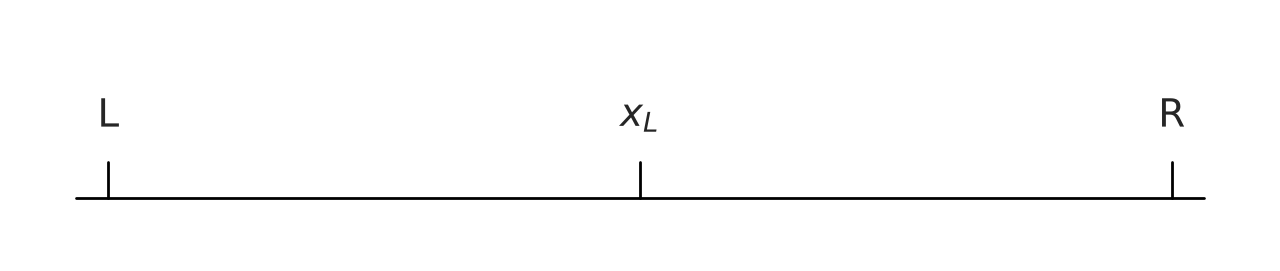

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# plotting with a R-looking plotting style
sns.set_style('white')

# the book shows the line of Hotelling but not the R code of the figure
# firm L is at 0 and firm R is at 1
# x_L is the customer who is indifferent between the two firms
# (we put it in the middle of the line for the drawing)
positions = [0, 0.5, 1]
labels = ['L', '$x_L$', 'R']

plt.figure(figsize=(8, 1.5))

# the line
plt.plot([-0.03, 1.03], [0, 0], color='k', linewidth=1)

# a small tick and a label for each of the three points
for i in range(0, 3):
    plt.plot([positions[i], positions[i]], [0, 0.2], color='k', linewidth=1)
    plt.text(positions[i], 0.4, labels[i], ha='center', fontsize=14)

# no axes for this drawing
plt.ylim(-0.3, 1)
plt.axis('off')
plt.show()

## 7.3.1 Simulation of Hotelling Model

In [4]:
# setting the seed in Numpy
# the random numbers of Python are not the ones of R,
# so our results are close to the book but not the same
np.random.seed(123456789)

N = 1000  # number of markets
beta = 0.25  # demand parameter

# quality (vertical) measure
v = 3 + np.random.normal(size=N)

# costs for both firms.
cL = 3 + np.random.normal(size=N)
cR = 9 + np.random.normal(size=N)

# price function for each firm.
pL = (v + 1 + beta*cR + 2*beta*cL)/(3*beta)
pR = (-v - 1 + beta*cL + 2*beta*cR)/(3*beta)

# demand for firm L
xL = (v + 1 - beta*pL + beta*pR)/2

# adjusting values to make things nice.
# we keep the markets where the prices are positive
# and where the demand for firm L is between 0 and 1
# in Python each condition goes in brackets when we use &
index = (pL > 0) & (pR > 0) & (xL > 0) & (xL < 1)
cL1 = cL[index]
cR1 = cR[index]
pL1 = pL[index]
pR1 = pR[index]
xL1 = xL[index]
v1 = v[index]

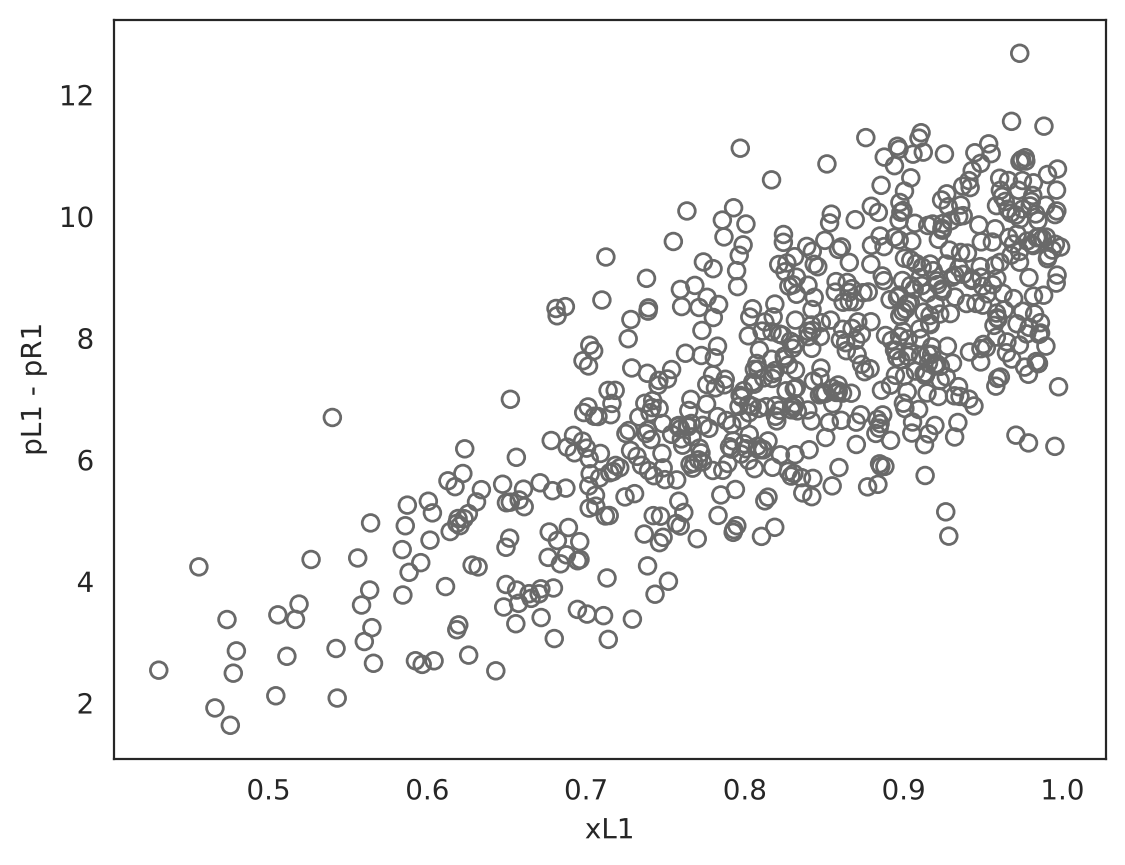

In [5]:
# demand for firm L by relative price of firm L to firm R
plt.scatter(xL1, pL1 - pR1, facecolors='none', color='dimgray')
plt.xlabel('xL1')
plt.ylabel('pL1 - pR1')
plt.show()

## 7.3.3 Cost Shifters

In [6]:
# using statsmodels and pandas, as in chapters 2 and 3
import statsmodels.formula.api as sm
import pandas as pd

# pack the variables in a dataframe
data = pd.DataFrame({'xL1': xL1, 'pL1': pL1, 'pR1': pR1,
                     'cL1': cL1, 'cR1': cR1, 'v1': v1})

# Intent to Treat
# I() computes the difference inside the formula, as in R
lm1 = sm.ols(formula="xL1 ~ I(cL1 - cR1)", data=data).fit()

# First stage
lm2 = sm.ols(formula="I(pL1 - pR1) ~ I(cL1 - cR1)", data=data).fit()

# IV estimate
# the slope is the second coefficient, at position 1 in Python
# the true value is -0.125
print(lm1.params.iloc[1]/lm2.params.iloc[1])

-0.03451216576783032


We take the bootstrap IV function of chapter 3:

In [7]:
# in python the inverse matrix can be found using
# the inv() function (from Numpy)
from numpy.linalg import inv

def lm_iv(y, X_in, Z_in=None, Reps=100, min_in=0.05, max_in=0.95):
    """
    Bootstrap IV estimator
    * takes in the y variable, the x explanatory variables
      and the z variables if available
    * without z variables, the x variables are used in place of z
      and the result is the OLS estimator
    * the "=" creates a default value for the local variables
    """

    # set up
    np.random.seed(123456789)
    if Z_in is None:
        Z_in = X_in
    N = len(y)  # number of observations
    X = np.c_[np.ones(N), X_in]  # adds a column of 1's to the matrix
    Z = np.c_[np.ones(N), Z_in]

    # bootstrap
    # create an empty list to fill with the estimates
    rows = []
    for r in range(0, Reps):
        # we draw N row numbers at random, with replacement
        # python starts counting at 0, so the rows go from 0 to N-1
        index_bs = np.random.randint(0, N, size=N)
        y_bs = y[index_bs]  # note y is a vector
        X_bs = X[index_bs, :]
        Z_bs = Z[index_bs, :]
        rows.append(inv(Z_bs.T.dot(X_bs)).dot(Z_bs.T).dot(y_bs))

    # stacking all the estimates in a single dataframe
    # one row per bootstrap sample, one column per coefficient
    bs_mat = pd.DataFrame(rows)

    # present results
    tab_res = pd.DataFrame()
    tab_res['coef'] = bs_mat.mean()
    tab_res['sd'] = bs_mat.std()
    tab_res[str(min_in)] = bs_mat.quantile(min_in)
    tab_res[str(max_in)] = bs_mat.quantile(max_in)

    # returns the tab_res dataframe
    return tab_res

In [8]:
# concatenating the vectors in a matrix (cbind in R)
X1 = np.c_[pL1, pR1]
Z1 = np.c_[cL1, cR1]
Y1 = xL1

# using the function defined in chapter 3.
tab_ols = lm_iv(Y1, X1, Reps=500)
tab_iv = lm_iv(Y1, X1, Z1, Reps=500)

# name the rows of the two tables
tab_ols.index = ['intercept', 'pL1', 'pR1']
tab_iv.index = ['intercept', 'pL1', 'pR1']

# we keep the first two columns of each table (coef and sd)
# and we put the OLS and the IV results side by side
tab_res = pd.concat([tab_ols[['coef', 'sd']], tab_iv[['coef', 'sd']]], axis=1)
tab_res.columns = ['OLS coef', 'OLS sd', 'IV coef', 'IV sd']

In [9]:
# the two prices are now separated
# the true values are -0.125 for pL1 and 0.125 for pR1
tab_res

,OLS coef,OLS sd,IV coef,IV sd
intercept,0.512937,0.028059,0.988522,0.075313
pL1,0.042886,0.002549,-0.027163,0.008525
pR1,-0.045060,0.002778,0.043469,0.009394


## 7.3.4 Demand Shifters

In [10]:
# regression of the price of firm L on the quality measure v
lm1 = sm.ols(formula="pL1 ~ v1", data=data).fit()
b1 = lm1.params['v1']

# in the model the slope b1 is equal to 1/(3*beta), which gives beta
beta = 1/(3*b1)

# and the slope of demand is -beta/2 (true value -0.125)
print(-beta/2)

-0.11286938610237873


## 7.5.1 Dominick's Data for Cereal

In [11]:
# the first column of the file has no name, it holds the row names of R
# we use it as the index of the dataframe
x = pd.read_csv('../data/dominicks.csv', index_col=0)
x.head()

,store,UPC,WEEK,ozprice,price,sig,mfr,calories,protein,fat,...,zone,age9,income,hhlarge,workwom,unemp,poverty,quaker,post,kellogg
1,100,3800001621,385,0.027889,1.20,-1.196872,K,0,0,-2,...,11.0,0.184361,10.036575,0.216354,0.267234,0.240075,0.166714,0,0,1
2,100,4300011460,388,-0.084667,-0.53,-0.731458,K,10,-3,-1,...,11.0,0.184361,10.036575,0.216354,0.267234,0.240075,0.166714,0,0,1
3,100,3000006610,398,-0.023292,-0.14,-1.460580,Q,10,-5,0,...,11.0,0.184361,10.036575,0.216354,0.267234,0.240075,0.166714,1,0,0
4,100,1600068350,395,-0.232667,-3.49,-5.775263,G,30,-3,-1,...,11.0,0.184361,10.036575,0.216354,0.267234,0.240075,0.166714,0,0,0
5,100,1600069320,399,0.032718,-0.04,-0.972771,G,0,-5,-1,...,11.0,0.184361,10.036575,0.216354,0.267234,0.240075,0.166714,0,0,0


In [12]:
# the price variable
p = x['ozprice']

# changes the scale of the variables for presentation
x['fat'] = x['fat']/100
x['oz'] = x['oz']/100
x['sodium'] = x['sodium']/1000
x['carbo'] = x['carbo']/100

# sig (sigma) refers to the adjusted measure of market share
# discussed above
# fat, carbo, sodium and fiber refer to cereal ingredients
# oz is the size of the package (ounces)
# quaker, post and kellogg are dummies for major cereal brands
# age9 is a measure of children in the household
# hhlarge is a measure of household size.
# R keeps the columns in the order of the dataset,
# so we write the names in this order
W_names = ['sig', 'fat', 'sodium', 'fiber', 'carbo', 'oz',
           'age9', 'hhlarge', 'quaker', 'post', 'kellogg']
W = x[W_names]

## 7.5.2 Instrument for Price of Cereal

In [13]:
# same variables as in W, but the instrument income replaces sig
Z_names = ['income', 'fat', 'sodium', 'fiber', 'carbo', 'oz',
           'age9', 'hhlarge', 'quaker', 'post', 'kellogg']
Z = x[Z_names]

The data has missing values, and the matrix algebra of `lm_iv` does not work with them. The book does not show how they are removed. We keep the rows with no missing value in p, W and Z.

In [14]:
# True for the rows with at least one missing value
# (the sum of a row is NA when one of its values is NA)
index_na = pd.concat([p, W, Z], axis=1).sum(axis=1, skipna=False).isna()

# we use numpy arrays (and not pandas dataframes)
# to pick the rows by their position in the bootstrap
p2 = np.array(p[index_na==False])
W2 = np.array(W[index_na==False])
Z2 = np.array(Z[index_na==False])

# number of rows in the data, and number of rows we keep
print(len(p), len(p2))

88160 74056


In [15]:
# using the IV function from Chapter 3
tab_ols = lm_iv(p2, W2, Reps=300)
tab_iv = lm_iv(p2, W2, Z2, Reps=300)

# name the rows of the two tables
tab_ols.index = ['intercept'] + W_names
tab_iv.index = ['intercept'] + W_names

# OLS and IV results side by side
tab_res = pd.concat([tab_ols[['coef', 'sd']], tab_iv[['coef', 'sd']]], axis=1)
tab_res.columns = ['OLS coef', 'OLS sd', 'IV coef', 'IV sd']

In [16]:
tab_res

,OLS coef,OLS sd,IV coef,IV sd
intercept,-0.011206,0.001161,0.290705,2.206800
sig,0.025515,0.000202,0.163542,1.012991
fat,-0.896671,0.034499,1.427671,17.629200
sodium,-0.101689,0.005429,-0.590462,3.679189
fiber,-0.008968,0.000126,0.004594,0.094116
carbo,-0.070867,0.008939,1.383425,10.526810
oz,-0.479871,0.004919,-0.485221,0.073092
age9,0.162120,0.010952,-0.043135,1.762821
hhlarge,-0.035166,0.009403,-0.152265,0.536173
quaker,-0.029149,0.000982,-0.101285,0.520235


## 7.5.3 Demand for Apple Cinnamon Cheerios

In [17]:
# transformation into "demand"
# tab_iv[2] in R is the second number of the table,
# which is the IV coefficient of sig
beta = -1/(2*tab_iv.loc['sig', 'coef'])

# transform gammas back.
gamma = -tab_iv['coef']/beta

# puts in the causal effect of price on demand.
gamma['sig'] = beta
gamma = gamma.rename({'sig': 'price'})
gamma

intercept    0.095085
price       -3.057325
fat          0.466967
sodium      -0.193130
fiber        0.001503
carbo        0.452495
oz          -0.158708
age9        -0.014109
hhlarge     -0.049803
quaker      -0.033129
post        -0.014551
kellogg     -0.037196
Name: coef, dtype: float64

Two things to know on the code of the book for the next cells. The coefficient named price is multiplied by the first column of W, which is sig and not the price. And the rows of the data are not sorted by product, so a column of `exp_delta` is not one product, and the values picked with `x$UPC==upc` in the second loop are not all from this product (it works for Apple Cinnamon Cheerios, because the same cells are replaced and then read). We keep the code as it is, to compare our numbers with the book.

In [18]:
# W and gamma become numpy arrays for the matrix multiplications
# W has all the rows of the data, also the ones with missing values
W = np.array(W)
gamma = np.array(gamma)

# the stores, the weeks and the number of products
# .unique() gives the values in order of appearance, as unique() in R
stores = x['store'].unique()
weeks = x['WEEK'].unique()
Ts = len(stores)
Tw = len(weeks)
J = len(x['UPC'].unique())

# one row for each store and week, with J values in each row
exp_delta = np.zeros((Ts*Tw, J))

t = 0  # python starts counting at 0
for ts in range(0, Ts):
    store = stores[ts]
    for tw in range(0, Tw):
        week = weeks[tw]
        # True for the J rows of the data of this store and this week
        index = np.array((x['WEEK']==week) & (x['store']==store))
        W_temp = W[index, :]
        # a column of 1's for the intercept, then W
        exp_delta[t, :] = np.exp(np.c_[np.ones(J), W_temp].dot(gamma))
        t = t + 1

# estimated shares in each store and week
# np.nansum and np.nanmean leave out the missing values (na.rm = TRUE in R)
# keepdims=True keeps the sums in a column, to divide each row by its own sum
share_est = exp_delta/(1 + np.nansum(exp_delta, axis=1, keepdims=True))

# summary of the means of the columns (the book calls them products)
# .describe() gives the numbers of summary() in R
pd.Series(np.nanmean(share_est, axis=0)).describe()

count    58.000000
mean      0.018734
std       0.002413
min       0.013598
25%       0.017326
50%       0.018849
75%       0.020206
max       0.024610
dtype: float64

In [19]:
# Apple cinnamon cheerios "family size"
# the UPC is a number in our dataframe, so no quotes
upc_acc = 1600062760

# the book also takes here the mean of a column "share" for this product
# the data has no such column and this mean is not used after, so we leave it out

K = 20
# range of relative prices
min_k = -6
max_k = -2
diff_k = (max_k - min_k)/K

# True for the rows of Apple Cinnamon Cheerios, and their number
index_acc = np.array(x['UPC']==upc_acc)
n_acc = sum(index_acc)

# the products, sorted as in the book
upcs = np.sort(x['UPC'].unique())

# create an empty list to fill with the points of the demand curve
rows = []

min_t = min_k
for k in range(0, K):
    pr = min_t + diff_k

    # when a matrix is indexed with one vector, R reads it as one long vector,
    # column after column. flatten(order='F') does the same in Python
    exp_delta2 = exp_delta.flatten(order='F')

    # new values for Apple Cinnamon Cheerios: the relative price pr
    # replaces the first column of W (python starts counting at 0)
    X_acc = np.c_[np.ones(n_acc), pr*np.ones(n_acc), W[index_acc, 1:]]
    exp_delta2[index_acc] = np.exp(X_acc.dot(gamma))

    # mean value for each product
    ave_share = np.zeros(J)
    for i in range(0, J):
        upc = upcs[i]
        ave_share[i] = np.nanmean(exp_delta2[np.array(x['UPC']==upc)])

    # from the mean values to the shares
    ave_share = ave_share/(1 + np.nansum(ave_share))

    # store the relative price and the share of Apple Cinnamon Cheerios
    rows.append([pr, ave_share[upcs==upc_acc][0]])
    min_t = min_t + diff_k

acc_demand = pd.DataFrame(rows, columns=['pr', 'share'])

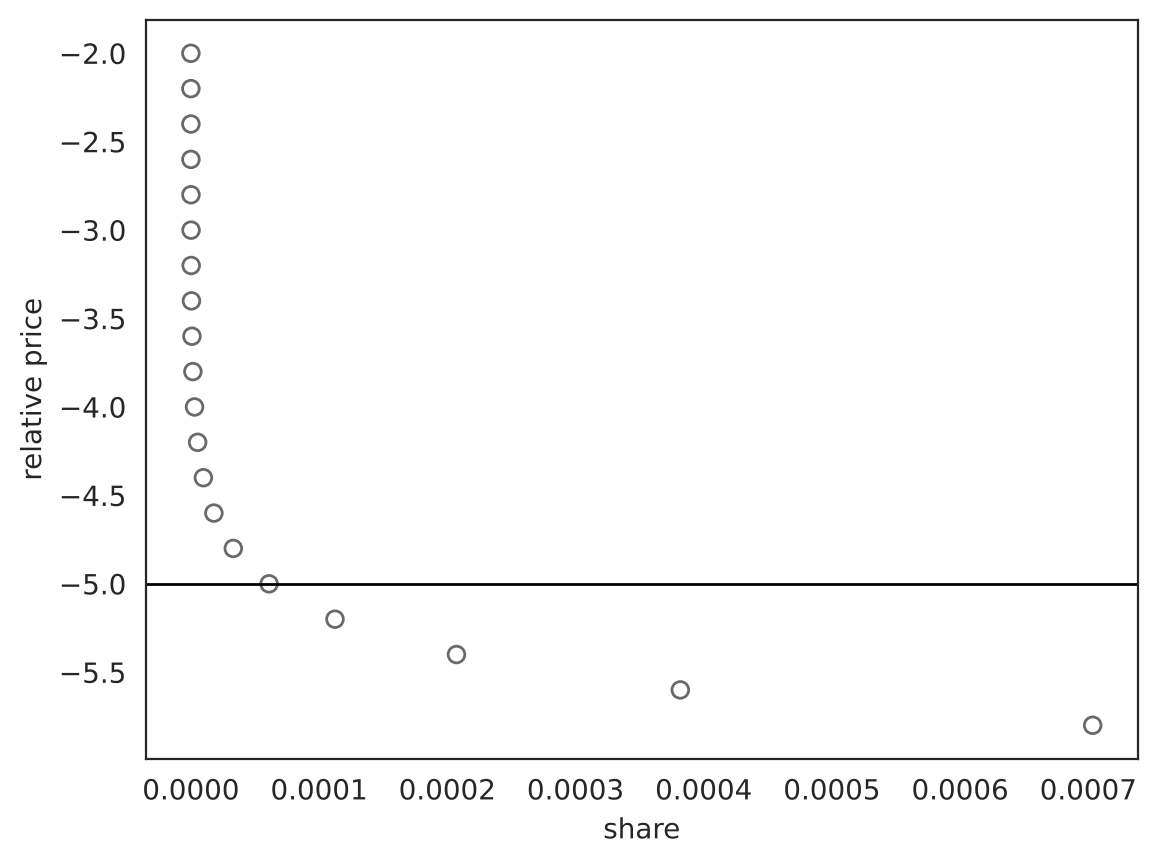

In [20]:
# demand for family size Apple Cinnamon Cheerios
plt.scatter(acc_demand['share'], acc_demand['pr'], facecolors='none', color='dimgray')

# the horizontal line of the book, at a relative price of -5
# (the book calls it the average relative price)
plt.axhline(y=-5, color='k', linewidth=1)
plt.xlabel('share')
plt.ylabel('relative price')
plt.show()

## 7.5.4 Value of Apple Cinnamon Cheerios

Our value is far below the 271,800 dollars of the book. The shares depend a lot on the IV coefficient of sig, which is not precise (a sd of 1): the bootstrap gives 0.16 here and 0.30 in the book. With the IV estimates printed in the book, the same code gives the value of the book.

In [21]:
# area of the triangle under the demand curve,
# between the relative prices -5 and -3
# row 5 of acc_demand in R is at position 4 in Python (relative price of -5)
pr_5 = acc_demand.loc[4, 'pr']
share_5 = acc_demand.loc[4, 'share']

# 267888011 is the total revenue in the original Dominicks sales data
# 52/367 gives the amount for one year (the data has 367 weeks)
print(0.5*(-3 - pr_5)*share_5*267888011*(52/367))

2315.0499192645516
